# WP2: Unsupervised Clustering for Early Anomaly Detection (Wind Farm B)

### How does Unsupervised Clustering detect developing anomalies in Time Series?
1. **Training on Normal Operating Regimes (`train_test == 'train'` & `status_type_id == 0`):**
   - A wind turbine naturally operates in several distinct normal regimes (e.g., low wind/cut-in, medium wind/cubic ramp, high wind/rated power with blade pitching, warm summer vs. cold winter).
   - Clustering groups these normal states into dense clusters in feature/PCA space.
2. **Scoring Developing Anomalies (`train_test == 'prediction'`):**
   - As a component degrades (e.g., transformer cell overheating in Events `34, 7, 19` or rotor/main bearing damage in Events `53, 27, 77`), its sensor state drifts away from the normal clusters.
   - We measure **how far each 10-minute timestamp is from the normal clusters**:
     - **Gaussian Mixture Model (GMM):** Negative log-likelihood (Mahalanobis distance across all clusters).
     - **K-Means:** Euclidean distance to the nearest cluster centroid.
     - **HDBSCAN:** Density-based outlier score.
3. **Temporal Persistence Smoothing (Crucial for Time Series!):**
   - A single wind gust can cause a 10-minute spike. To prevent false alarms, we apply a **rolling persistence filter** (e.g., alarm triggers only when $\ge 50\%$ of timestamps over a **12-hour / 72-step window** exceed the $99.\text{5th}$ percentile of normal training distances).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

plt.style.use('seaborn-v0_8-whitegrid')
DATA_DIR = Path(r"D:\Bootcamp\Projects\wind-turbine-anomaly-detection\data\raw\Wind Farm B")
DATASETS_DIR = DATA_DIR / "datasets"
event_info = pd.read_csv(DATA_DIR / "event_info.csv", sep=";")
event_info["event_start"] = pd.to_datetime(event_info["event_start"])
event_info["event_end"] = pd.to_datetime(event_info["event_end"])

In [2]:
# Self-contained WP1 preprocessing function (reused from Notebook 01)
def load_and_preprocess(event_id: int, pca_variance: float = 0.95):
    df = pd.read_csv(DATASETS_DIR / f"{event_id}.csv", sep=";")
    df["time_stamp"] = pd.to_datetime(df["time_stamp"])
    data = df.sort_values("time_stamp").reset_index(drop=True)
    meta_cols = ["time_stamp", "asset_id", "id", "train_test", "status_type_id"]

    # Drop cumulative counters
    drop_cols = [c for c in data.columns if c.startswith(("sensor_0_", "sensor_1_", "sensor_2_", "sensor_3_"))]
    data.drop(columns=drop_cols, inplace=True)

    # Interpolate short gaps
    num_cols = [c for c in data.columns if c not in meta_cols]
    data[num_cols] = data[num_cols].interpolate(method="linear", limit=6)

    # Cyclic encoding for angles
    for angle_base in ["sensor_4", "sensor_10", "sensor_21"]:
        col = f"{angle_base}_avg"
        if col in data.columns:
            rad = np.deg2rad(data[col] % 360.0)
            data[f"{col}_sin"] = np.sin(rad)
            data[f"{col}_cos"] = np.cos(rad)
            raw_angle_cols = [c for c in data.columns if c.startswith(f"{angle_base}_") and not c.endswith(("_sin", "_cos", "_std"))]
            data.drop(columns=raw_angle_cols, inplace=True)

    # Thermal differentials (Component Temp - Outside Temp sensor_8_avg)
    delta_t_cols = {}
    if "sensor_8_avg" in data.columns:
        outside_t = data["sensor_8_avg"]
        for tid in range(31, 54):
            tcol = f"sensor_{tid}_avg"
            if tcol in data.columns:
                delta_t_cols[f"sensor_{tid}_delta_T"] = data[tcol] - outside_t
    if delta_t_cols:
        data = pd.concat([data, pd.DataFrame(delta_t_cols, index=data.index)], axis=1)

    # 24h rolling mean on thermal differentials & vibrations
    key_roll_cols = list(delta_t_cols.keys()) + ["sensor_54_avg", "sensor_55_avg", "sensor_56_avg", "power_62_avg"]
    key_roll_cols = [c for c in key_roll_cols if c in data.columns]
    rolled_24h = data[key_roll_cols].rolling(window=144, min_periods=1).mean().add_suffix("_roll24h")
    data = pd.concat([data, rolled_24h], axis=1)

    # Fit RobustScaler + PCA on normal training data only
    feature_cols = [c for c in data.columns if c not in meta_cols]
    train_normal_mask = (data["train_test"] == "train") & (data["status_type_id"] == 0)
    train_medians = data.loc[train_normal_mask, feature_cols].median()
    X_all = data[feature_cols].fillna(train_medians).fillna(0.0)

    scaler = RobustScaler().fit(X_all.loc[train_normal_mask])
    X_scaled = np.clip(scaler.transform(X_all), -15.0, 15.0)

    pca = PCA(n_components=pca_variance, random_state=42).fit(X_scaled[train_normal_mask.values])
    X_pca = pca.transform(X_scaled)

    return data[meta_cols].copy(), X_pca

---
## Step 1: Selecting Optimal Number of Clusters ($k$) on Normal Training Data

Before running anomaly detection, we justify our choice of cluster count $k$ using:
- **Silhouette Score** (higher = denser, better-separated clusters)
- **Davies-Bouldin Index** (lower = better separation)
- **BIC (Bayesian Information Criterion)** for Gaussian Mixture Models

In [3]:
meta_34, X_34_pca = load_and_preprocess(34)
train_norm_idx = (meta_34["train_test"] == "train") & (meta_34["status_type_id"] == 0)
X_train_sub = X_34_pca[train_norm_idx.values][::6]  # Hourly subsample for fast cluster selection

k_values = [2, 3, 4, 5, 6, 8]
tuning_rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_train_sub)
    gmm = GaussianMixture(n_components=k, covariance_type="full", reg_covar=1e-3, random_state=42).fit(X_train_sub)
    tuning_rows.append({
        "k": k,
        "KMeans_Silhouette": round(silhouette_score(X_train_sub, km.labels_), 4),
        "KMeans_DaviesBouldin": round(davies_bouldin_score(X_train_sub, km.labels_), 4),
        "GMM_BIC": round(gmm.bic(X_train_sub), 1),
    })

df_tuning = pd.DataFrame(tuning_rows)
display(df_tuning)

,k,KMeans_Silhouette,KMeans_DaviesBouldin,GMM_BIC
0,2,0.5197,0.7799,708872.7
1,3,0.2526,1.3867,665751.6
2,4,0.2560,1.4557,646509.9
3,5,0.2500,1.4492,617274.6
4,6,0.2368,1.4796,605140.7
5,8,0.2290,1.4351,593218.5


---
## Step 2: Visualizing Clustering Anomaly Detection on an Anomaly Event (`34`) vs. Normal Event (`52`)

Both Event `34` (Anomaly) and Event `52` (Normal Control) come from **Asset 14**! Comparing them side-by-side is the ultimate proof that our clustering model detects the developing fault early without raising false alarms during normal operation.

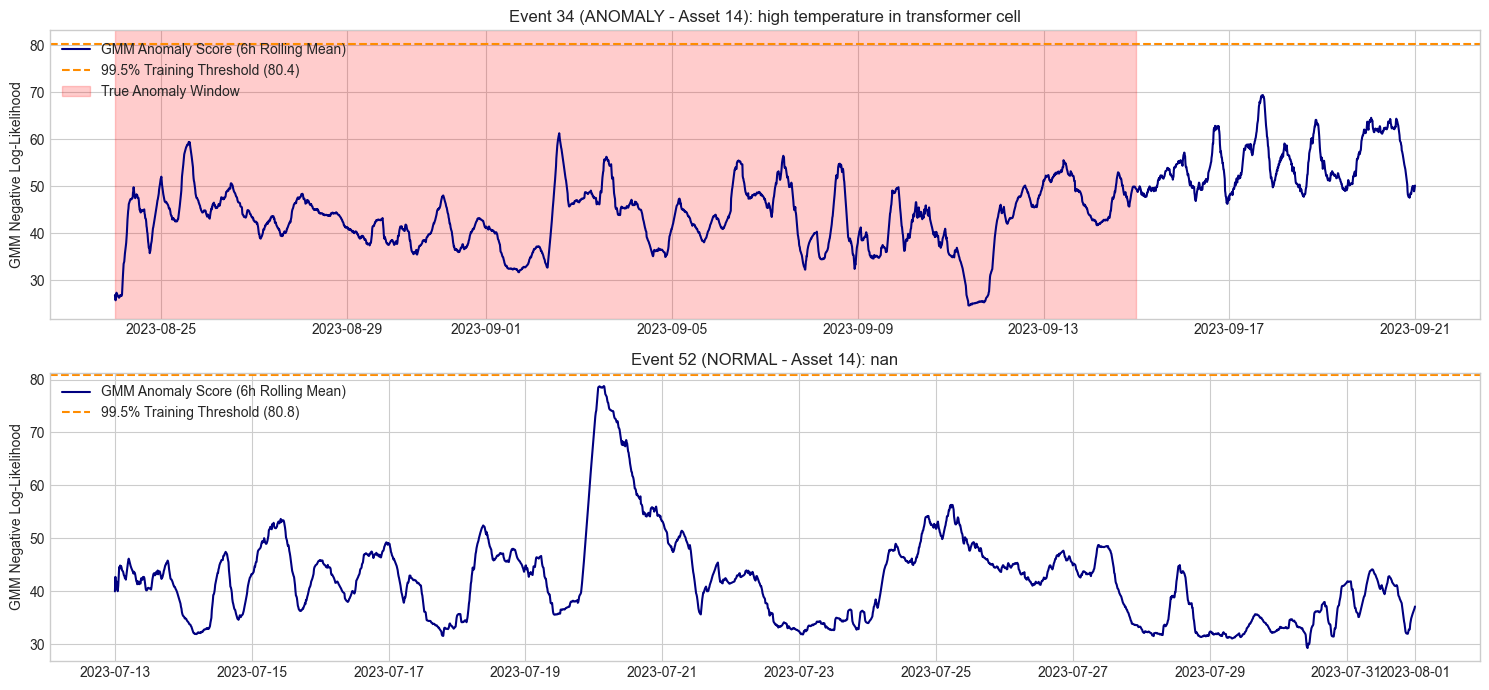

In [4]:
def run_clustering_detector(
    meta_df: pd.DataFrame,
    X_pca: np.ndarray,
    method: str = "gmm",
    n_clusters: int = 5,
    threshold_pct: float = 99.5,
    persistence_window: int = 72,  # 12 hours
    persistence_ratio: float = 0.5
):
    train_norm = (meta_df["train_test"] == "train") & (meta_df["status_type_id"] == 0)
    X_train = X_pca[train_norm.values]

    if method == "gmm":
        model = GaussianMixture(n_components=n_clusters, covariance_type="full", reg_covar=1e-3, random_state=42)
        model.fit(X_train)
        train_scores = -model.score_samples(X_train)
        all_scores = -model.score_samples(X_pca)
    elif method == "kmeans":
        model = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
        model.fit(X_train)
        train_scores = np.min(model.transform(X_train), axis=1)
        all_scores = np.min(model.transform(X_pca), axis=1)
    else:
        raise ValueError("Choose 'gmm' or 'kmeans'")

    threshold = np.percentile(train_scores, threshold_pct)
    # Only flag anomalies when turbine is in normal operation (status_type_id == 0) to ignore scheduled service
    raw_flags = ((all_scores > threshold) & (meta_df["status_type_id"].values == 0)).astype(int)
    smoothed_flags = (
        pd.Series(raw_flags).rolling(window=persistence_window, min_periods=1).mean() >= persistence_ratio
    ).astype(int).values

    return all_scores, threshold, raw_flags, smoothed_flags

# Run on Event 34 (Anomaly) and Event 52 (Normal Control on same turbine Asset 14)
scores_34, thresh_34, raw_34, smooth_34 = run_clustering_detector(meta_34, X_34_pca, method="gmm", n_clusters=5)
meta_52, X_52_pca = load_and_preprocess(52)
scores_52, thresh_52, raw_52, smooth_52 = run_clustering_detector(meta_52, X_52_pca, method="gmm", n_clusters=5)

# Plot Prediction Windows Side-by-Side
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

for ax, ev_id, meta_df, scores, thresh, smooth in [
    (axes[0], 34, meta_34, scores_34, thresh_34, smooth_34),
    (axes[1], 52, meta_52, scores_52, thresh_52, smooth_52),
]:
    pred_mask = meta_df["train_test"] == "prediction"
    ts_pred = meta_df.loc[pred_mask, "time_stamp"]
    sc_pred = pd.Series(scores[pred_mask.values]).rolling(36, min_periods=1).mean()  # 6h smoothed score
    fl_pred = smooth[pred_mask.values]
    ev_row = event_info[event_info["event_id"] == ev_id].iloc[0]

    ax.plot(ts_pred, sc_pred, label="GMM Anomaly Score (6h Rolling Mean)", color="navy")
    ax.axhline(thresh, color="darkorange", linestyle="--", label=f"99.5% Training Threshold ({thresh:.1f})")
    if ev_row["event_label"] == "anomaly":
        ax.axvspan(ev_row["event_start"], ev_row["event_end"], color="red", alpha=0.2, label="True Anomaly Window")
    # Highlight detected alarm timestamps
    if np.any(fl_pred == 1):
        first_alarm_ts = ts_pred.iloc[int(np.argmax(fl_pred == 1))]
        ax.axvline(first_alarm_ts, color="crimson", linewidth=2, label=f"First Alarm: {first_alarm_ts}")
    ax.set_title(f"Event {ev_id} ({ev_row['event_label'].upper()} - Asset {ev_row['asset_id']}): {ev_row['event_description']}")
    ax.set_ylabel("GMM Negative Log-Likelihood")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()